# Compara surrogates y transfiere a minerales no vistos

Nivel: 3. Requisitos previos: Niveles 1 y 2 de este tema. Tiempo de lectura: 28 minutos.

## Objetivos

Compara familias de modelos con objetivos y filas de prueba idénticos, inspecciona transferencia de caso completo y cobertura GP, y evalúa los límites de generalización que permite la evidencia.

## Preparación

```bash
pip install numpy==2.2.6 scipy==1.17.1 pandas==2.2.3 matplotlib==3.11.2 nbclient==0.11.0 nbformat==5.11.1 ipykernel==7.4.0
```

El pipeline OreFlow se importa desde `data-pipeline/`; este notebook nunca instala paquetes.

Configura las importaciones y registra versiones. Este paso hace reproducible la ejecución del método.

In [1]:
# Importa herramientas de análisis y registra sus versiones exactas.
import importlib.metadata
import json
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Resuelve el pipeline local desde la estructura relativa del repositorio.
repo = Path('../../../').resolve()
sys.path.insert(0, str(repo / 'data-pipeline'))
for package in ('numpy', 'scipy', 'pandas', 'matplotlib', 'nbclient', 'nbformat', 'ipykernel'):
    print(package, importlib.metadata.version(package))

numpy 2.2.6
scipy 1.17.1
pandas 2.2.3
matplotlib 3.11.2
nbclient 0.11.0
nbformat 5.11.1
ipykernel 7.4.0


## Datos

Responsable: autores de OreFlow; `data/derived/learning.json` contiene resultados versionados de 3.072 estados simulados en doce circuitos de autoría propia, licencia MIT del proyecto. Las etiquetas las genera el motor, no son datos observados de planta. Repositorio: https://github.com/fsantibanezleal/CAOS_OreFlow.

## Método

El portafolio de producción incluye Ridge, random forest, histogram gradient boosting, proceso gaussiano y MLP PyTorch. Registra RMSE, MAE y $R^2$ en interpolación, caso no visto y grupo de mineral no visto. La cobertura empírica revisa intervalos GP nominales del 95%. La importancia por permutación indica dependencia en el dominio de prueba, no causalidad.

## Estado del arte

Random forests (Breiman, 2001), gradient boosting (Friedman, 2001), procesos gaussianos (Rasmussen y Williams, 2006) y redes entrenadas con Adam (Kingma y Ba, 2015) son métodos establecidos. OreFlow los compara en un diseño común generado por el motor y audita transferencia, métricas por caso, cobertura e identificación fuera de envolvente. No se afirma un algoritmo nuevo ni una mejora validada en planta; doce circuitos propios acotan lo que este registro respalda.

Read the committed production evaluation and its declared cases, model identities and split sizes.

In [2]:
# Read the committed production evaluation and its declared cases, model identities and split sizes.
record = json.loads((repo / 'data/derived/learning.json').read_text(encoding='utf-8'))
print('versión del motor:', record['engine_version'])
print('design:', record['design'])
print('models:', record['models'])
print('interpolation rows:', record['interpolation']['train_rows'], 'train /', record['interpolation']['test_rows'], 'test')
print('folds por caso:', len(record['leave_one_case_out']), '| group folds:', len(record['leave_one_group_out']))

versión del motor: 0.10.003
design: {'per_case': 256, 'cases': ['copper_porphyry_soft', 'copper_porphyry_hard', 'gold_free_milling', 'iron_magnetite_fine', 'nickel_sulphide', 'phosphate_clay', 'copper_molybdenum', 'copper_oxide', 'zinc_sulfide', 'mixed_ore_high_clay', 'low_grade_copper', 'refractory_gold'], 'rows': 3072, 'seed': 20260927, 'seconds': 895.4586591999978, 'method': "scrambled Sobol over each case's Contract 1 envelope and ore factors"}
models: ['ridge', 'random_forest', 'hist_gradient_boosting', 'gaussian_process', 'mlp']
interpolation rows: 2460 train / 612 test
folds por caso: 12 | group folds: 2


Compare recovery errors on the same interpolation rows. Pooled and within-case R² answer different questions.

In [3]:
# Compare recovery errors on the same interpolation rows.
target = 'recovery_pct'
rows = []
for name, values in record['interpolation']['models'].items():
    metric = values[target]
    rows.append({'model': name, 'RMSE (%)': metric['rmse'], 'MAE (%)': metric['mae'],
                 'pooled R²': metric['r2'], 'within-case R²': metric['r2_within_case']})
score = pd.DataFrame(rows).set_index('model').sort_values('RMSE (%)')
display(score.round(3))

,RMSE (%),MAE (%),pooled R²,within-case R²
model,,,,
mlp,3.382,1.675,0.951,0.936
hist_gradient_boosting,4.603,3.178,0.909,0.881
gaussian_process,5.344,3.600,0.878,0.840
random_forest,6.492,4.538,0.820,0.764
ridge,9.460,6.825,0.617,0.498


Plot RMSE by target, retaining target units. Compare models within each column; do not rank recovery, log-upgrade and energy on one raw scale.

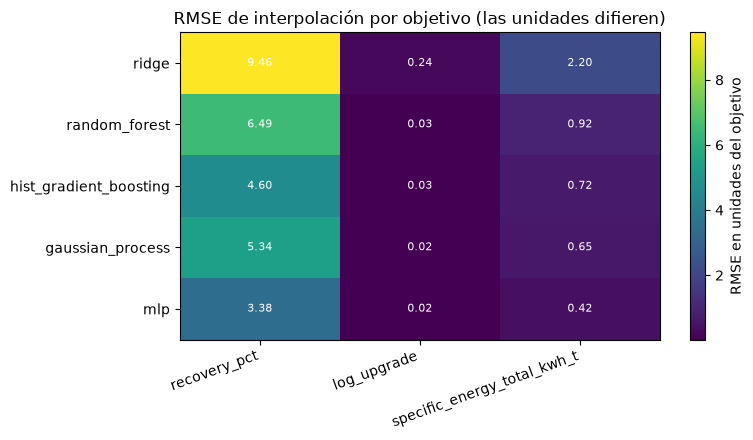

In [4]:
# Plot RMSE by target, retaining target units.
model_names, targets = record['models'], record['targets']
rmse = np.array([[record['interpolation']['models'][m][t]['rmse'] for t in targets] for m in model_names])
fig, ax = plt.subplots(figsize=(8, 4.5))
im = ax.imshow(rmse, aspect='auto', cmap='viridis')
ax.set_xticks(range(len(targets)), targets, rotation=20, ha='right'); ax.set_yticks(range(len(model_names)), model_names)
ax.set_title('RMSE de interpolación por objetivo (las unidades difieren)')
for i in range(len(model_names)):
    for j in range(len(targets)): ax.text(j, i, f'{rmse[i,j]:.2f}', ha='center', va='center', color='white', fontsize=8)
fig.colorbar(im, ax=ax, label='RMSE en unidades del objetivo'); fig.tight_layout()

Inspect whole-case transfer and interval coverage. A strong interpolation result does not promise performance for an ore group absent from training.

In [5]:
# Inspect whole-case transfer and interval coverage.
case_scores = [{'held-out case': f['held_out'], 'RMSE (%)': f['models']['random_forest']['recovery_pct']['rmse']} for f in record['leave_one_case_out']]
group_scores = [{'held-out ore group': f['held_out_group'], 'RMSE (%)': f['models']['random_forest']['recovery_pct']['rmse']} for f in record['leave_one_group_out']]
print('Worst leave-one-case-out recovery scores:')
display(pd.DataFrame(case_scores).sort_values('RMSE (%)', ascending=False).head(5))
print('Leave-one-ore-group-out recovery scores:')
display(pd.DataFrame(group_scores).sort_values('RMSE (%)', ascending=False))
gp = record['interpolation']['models']['gaussian_process']
print('cobertura nominal 95% del intervalo GP:', {t: gp[t]['coverage_95'] for t in targets})

Worst leave-one-case-out recovery scores:


,held-out case,RMSE (%)
3,iron_magnetite_fine,48.862763
11,refractory_gold,15.406035
7,copper_oxide,14.117908
2,gold_free_milling,12.480387
8,zinc_sulfide,11.880682


Leave-one-ore-group-out recovery scores:


,held-out ore group,RMSE (%)
0,Cu:chalcopyrite,13.925760
1,Au:pyrite,10.712957


cobertura nominal 95% del intervalo GP: {'recovery_pct': 0.9068627450980392, 'log_upgrade': 0.9133986928104575, 'specific_energy_total_kwh_t': 0.9362745098039216}


## Resultados

Compara el mapa de calor dentro de cada objetivo. La brecha entre R² agrupado y dentro de caso evidencia efectos de medias por caso. Retenciones de casos y grupos son pruebas de transferencia más exigentes, no garantías en plantas futuras. La cobertura GP es empírica en esta partición generada. Todas las etiquetas proceden del motor; para validación en terreno se requieren datos independientes de planta.

## Resumen

El resultado acotado es que los surrogates aproximan el motor OreFlow en doce circuitos de autoría propia. El notebook informa cómo cambian las métricas con retenciones estrictas, sin afirmar capacidad predictiva general en planta ni un algoritmo nuevo.

## Referencias

- https://doi.org/10.1023/A:1010933404324
- https://doi.org/10.1214/aos/1013203451
- https://doi.org/10.48550/arXiv.1412.6980
- https://doi.org/10.1017/CBO9780511790423
- https://doi.org/10.1023/A:1010933404324